<a href="https://colab.research.google.com/github/subhdeeep/Netflix-Network-Traffic-Classification/blob/main/Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

In [ ]:
import os
import zipfile
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42


In [ ]:
# The ZIP file was not found in Drive, but the extracted CSV is already available locally in Colab!
DATA_PATH = '/content/Netflix_1.csv'

import os
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f'Cannot find dataset at {DATA_PATH}')

print('Dataset found ready for use:', DATA_PATH)

Dataset found ready for use: /content/Netflix_1.csv


In [ ]:
# Load the extracted CSV directly (do not use zipfile here)
df = pd.read_csv(
    DATA_PATH,
    usecols=['Time', 'Protocol', 'Length'],
    dtype={'Protocol': 'category'},
    low_memory=False
)

print('Dataset shape:', df.shape)
display(df.head())
print('\nData types:')
print(df.dtypes)
print('\nProtocol labels:')
print(df['Protocol'].value_counts(dropna=False))

Dataset shape: (4290778, 3)


,Time,Protocol,Length
0,2022-06-17 23:48:34.871426,TCP,60
1,2022-06-17 23:48:34.953834,TCP,60
2,2022-06-17 23:48:35.035546,TCP,48
3,2022-06-17 23:48:35.035900,TCP,40
4,2022-06-17 23:48:35.037489,TCP,552



Data types:
Time          object
Protocol    category
Length         int64
dtype: object

Protocol labels:
Protocol
TCP        3942556
TLSv1.3     348222
Name: count, dtype: int64


In [ ]:
print('Missing values before cleaning:')
print(df.isna().sum())

# Convert types safely.
df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
df['Length'] = pd.to_numeric(df['Length'], errors='coerce')
df['Protocol'] = df['Protocol'].astype('string').str.strip()

# Drop records missing any field required for this project.
df = df.dropna(subset=['Time', 'Protocol', 'Length']).copy()
df = df[df['Length'] > 0].copy()
df = df[df['Protocol'] != ''].copy()

# Use compact numeric storage after validation.
df['Length'] = df['Length'].astype('int32')
df = df.sort_values('Time', kind='mergesort').reset_index(drop=True)

print('Shape after cleaning:', df.shape)
print('Missing values after cleaning:')
print(df[['Time', 'Protocol', 'Length']].isna().sum())
print('Protocol counts:')
print(df['Protocol'].value_counts())

Missing values before cleaning:
Time        0
Protocol    0
Length      0
dtype: int64
Shape after cleaning: (4290778, 3)
Missing values after cleaning:
Time        0
Protocol    0
Length      0
dtype: int64
Protocol counts:
Protocol
TCP        3942556
TLSv1.3     348222
Name: count, dtype: Int64


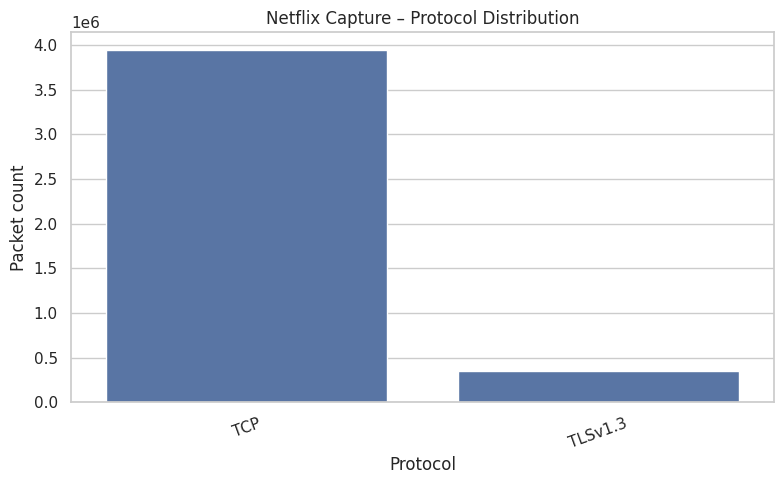

Protocol
TCP        3942556
TLSv1.3     348222
Name: count, dtype: Int64


In [ ]:
# 3.1 Protocol distribution
protocol_counts = df['Protocol'].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=protocol_counts.index.astype(str), y=protocol_counts.values)
plt.title('Netflix Capture – Protocol Distribution')
plt.xlabel('Protocol')
plt.ylabel('Packet count')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(protocol_counts)

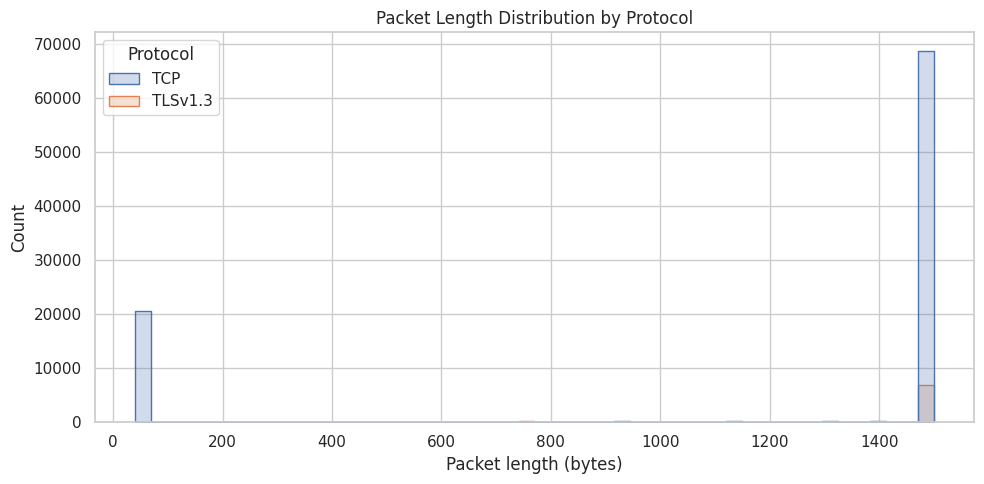

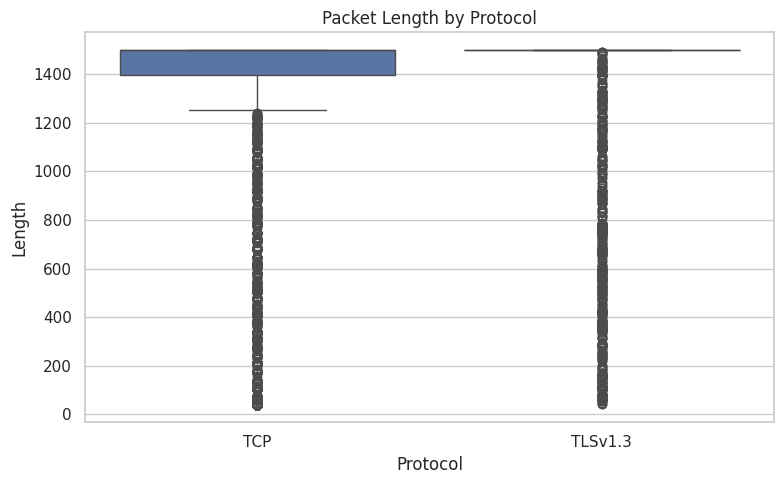

In [ ]:
# Sample for packet-length plots
eda_sample = df.sample(n=min(100_000, len(df)), random_state=RANDOM_STATE)

# 3.2 Packet length distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=eda_sample, x='Length', hue='Protocol', bins=50, element='step')
plt.title('Packet Length Distribution by Protocol')
plt.xlabel('Packet length (bytes)')
plt.tight_layout()
plt.show()

# 3.3 Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=eda_sample, x='Protocol', y='Length')
plt.title('Packet Length by Protocol')
plt.tight_layout()
plt.show()

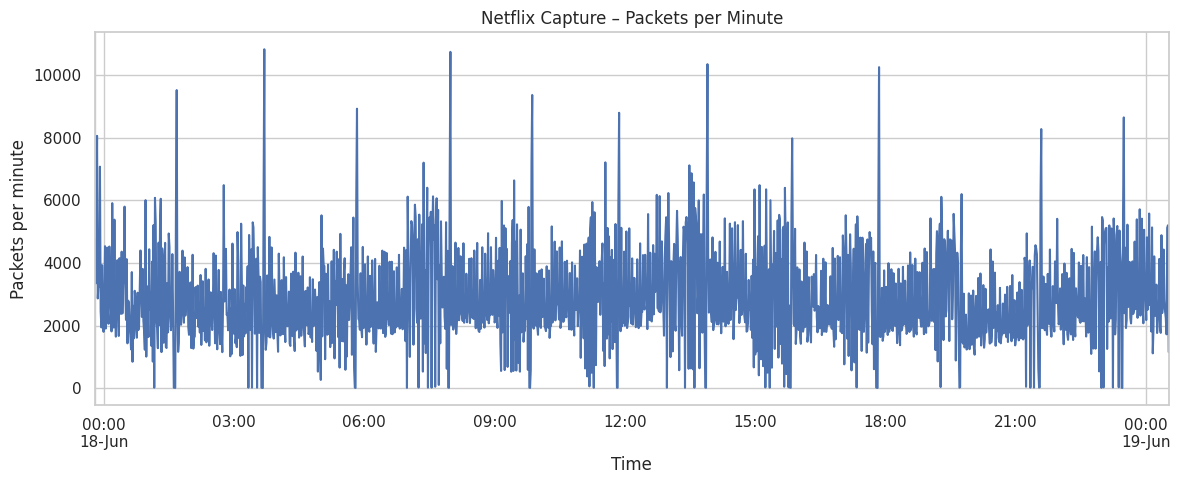

In [ ]:
# 3.4 Packets per minute over time
packets_per_minute = (
    df.set_index('Time')
      .resample('1min')
      .size()
)

plt.figure(figsize=(12, 5))
packets_per_minute.plot()
plt.title('Netflix Capture – Packets per Minute')
plt.xlabel('Time')
plt.ylabel('Packets per minute')
plt.tight_layout()
plt.show()

In [ ]:
FEATURES = ['Length', 'delta_ms', 'prev_length', 'prev5_mean_length']
TARGET = 'Protocol'

def make_features(data):
    # Create packet-level numeric features in chronological order.
    out = data[['Time', 'Protocol', 'Length']].copy()
    out['Time'] = pd.to_datetime(out['Time'], errors='coerce')
    out['Length'] = pd.to_numeric(out['Length'], errors='coerce')
    out['Protocol'] = out['Protocol'].astype('string').str.strip()
    out = out.dropna(subset=['Time', 'Protocol', 'Length'])
    out = out[out['Length'] > 0].copy()
    out = out.sort_values('Time', kind='mergesort').reset_index(drop=True)

    out['delta_ms'] = out['Time'].diff().dt.total_seconds() * 1000
    out['prev_length'] = out['Length'].shift(1)
    out['prev5_mean_length'] = (
        out['Length'].shift(1).rolling(window=5, min_periods=1).mean()
    )
    return out

df_ml = make_features(df)
print('Feature dataset shape:', df_ml.shape)
display(df_ml.head(10))
print(df_ml[FEATURES].describe())

Feature dataset shape: (4290778, 6)


,Time,Protocol,Length,delta_ms,prev_length,prev5_mean_length
0,2022-06-17 23:48:34.871426,TCP,60,NaN,NaN,NaN
1,2022-06-17 23:48:34.953834,TCP,60,82.408,60.0,60.0
2,2022-06-17 23:48:35.035546,TCP,48,81.712,60.0,60.0
3,2022-06-17 23:48:35.035900,TCP,40,0.354,48.0,56.0
4,2022-06-17 23:48:35.037489,TCP,552,1.589,40.0,52.0
5,2022-06-17 23:48:35.037704,TCP,40,0.215,552.0,152.0
6,2022-06-17 23:48:35.037820,TLSv1.3,45,0.116,40.0,148.0
7,2022-06-17 23:48:35.038033,TCP,40,0.213,45.0,145.0
8,2022-06-17 23:48:35.118601,TLSv1.3,426,80.568,40.0,143.4
9,2022-06-17 23:48:35.118990,TCP,40,0.389,426.0,220.6


             Length      delta_ms   prev_length  prev5_mean_length
count  4.290778e+06  4.290777e+06  4.290777e+06       4.290777e+06
mean   1.170778e+03  2.073755e+01  1.170778e+03       1.170778e+03
std    5.985287e+02  8.054557e+02  5.985286e+02       3.115299e+02
min    4.000000e+01  3.000000e-03  4.000000e+01       4.000000e+01
25%    1.500000e+03  2.400000e-02  1.500000e+03       9.160000e+02
50%    1.500000e+03  4.100000e-02  1.500000e+03       1.208000e+03
75%    1.500000e+03  6.400000e-02  1.500000e+03       1.500000e+03
max    1.500000e+03  5.977572e+04  1.500000e+03       1.500000e+03


In [ ]:
split_index = int(len(df_ml) * 0.80)
train_full = df_ml.iloc[:split_index].copy()
test_full = df_ml.iloc[split_index:].copy()

print('Full training rows:', len(train_full))
print('Full holdout rows:', len(test_full))
print('Training class distribution:')
print(train_full[TARGET].value_counts())
print('Holdout class distribution:')
print(test_full[TARGET].value_counts())

Full training rows: 3432622
Full holdout rows: 858156
Training class distribution:
Protocol
TCP        3154054
TLSv1.3     278568
Name: count, dtype: Int64
Holdout class distribution:
Protocol
TCP        788502
TLSv1.3     69654
Name: count, dtype: Int64


In [ ]:
# Limit training sample per class for a first Colab experiment.
MAX_TRAIN_PER_CLASS = 5_000
MAX_TEST_ROWS = 10_000

train_parts = []
for label, group in train_full.groupby(TARGET, observed=True):
    train_parts.append(
        group.sample(
            n=min(MAX_TRAIN_PER_CLASS, len(group)),
            random_state=RANDOM_STATE
        )
    )

train_sample = (
    pd.concat(train_parts)
      .sort_values('Time', kind='mergesort')
      .reset_index(drop=True)
)

# Use a stratified sample of the holdout, retaining approximately natural prevalence.
test_sample, _ = train_test_split(
    test_full,
    train_size=min(MAX_TEST_ROWS, len(test_full)),
    stratify=test_full[TARGET],
    random_state=RANDOM_STATE
)

X_train = train_sample[FEATURES]
y_train = train_sample[TARGET].astype(str)
X_test = test_sample[FEATURES]
y_test = test_sample[TARGET].astype(str)

print('Training sample:', X_train.shape)
print('Testing sample:', X_test.shape)
print('Training labels:', y_train.value_counts().to_dict())
print('Testing labels:', y_test.value_counts().to_dict())

Training sample: (10000, 4)
Testing sample: (10000, 4)
Training labels: {'TLSv1.3': 5000, 'TCP': 5000}
Testing labels: {'TCP': 9188, 'TLSv1.3': 812}


In [ ]:
# Four algorithms. Scaling is useful for Logistic Regression and KNN;
# tree-based models do not require feature scaling.
models = {
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=500, class_weight='balanced'))
    ]),
    'KNN': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1))
    ]),
    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(
            max_depth=20, class_weight='balanced', random_state=RANDOM_STATE
        ))
    ]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(
            n_estimators=100, max_depth=20,
            class_weight='balanced_subsample',
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    print('Training:', name)
    model.fit(X_train, y_train)
    print('Completed:', name)

Training: Logistic Regression
Completed: Logistic Regression
Training: KNN
Completed: KNN
Training: Decision Tree
Completed: Decision Tree
Training: Random Forest
Completed: Random Forest


In [ ]:
results = []
predictions_by_model = {}

for name, model in models.items():
    predictions = model.predict(X_test)
    predictions_by_model[name] = predictions
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro Precision': precision_score(y_test, predictions, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, predictions, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, predictions, average='macro', zero_division=0)
    })
    print('\n' + name)
    print(classification_report(y_test, predictions, zero_division=0))

results_df = pd.DataFrame(results).sort_values('Macro F1', ascending=False)
display(results_df)


Logistic Regression
              precision    recall  f1-score   support

         TCP       0.93      0.59      0.72      9188
     TLSv1.3       0.10      0.50      0.16       812

    accuracy                           0.59     10000
   macro avg       0.51      0.55      0.44     10000
weighted avg       0.86      0.59      0.68     10000


KNN
              precision    recall  f1-score   support

         TCP       0.94      0.61      0.74      9188
     TLSv1.3       0.12      0.58      0.19       812

    accuracy                           0.61     10000
   macro avg       0.53      0.59      0.47     10000
weighted avg       0.88      0.61      0.70     10000


Decision Tree
              precision    recall  f1-score   support

         TCP       0.95      0.61      0.74      9188
     TLSv1.3       0.12      0.60      0.20       812

    accuracy                           0.61     10000
   macro avg       0.53      0.61      0.47     10000
weighted avg       0.88      0.61

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
2,Decision Tree,0.6115,0.532702,0.605585,0.471785
1,KNN,0.6063,0.528998,0.593773,0.466205
3,Random Forest,0.5859,0.530242,0.599512,0.457914
0,Logistic Regression,0.5859,0.514204,0.546184,0.444218


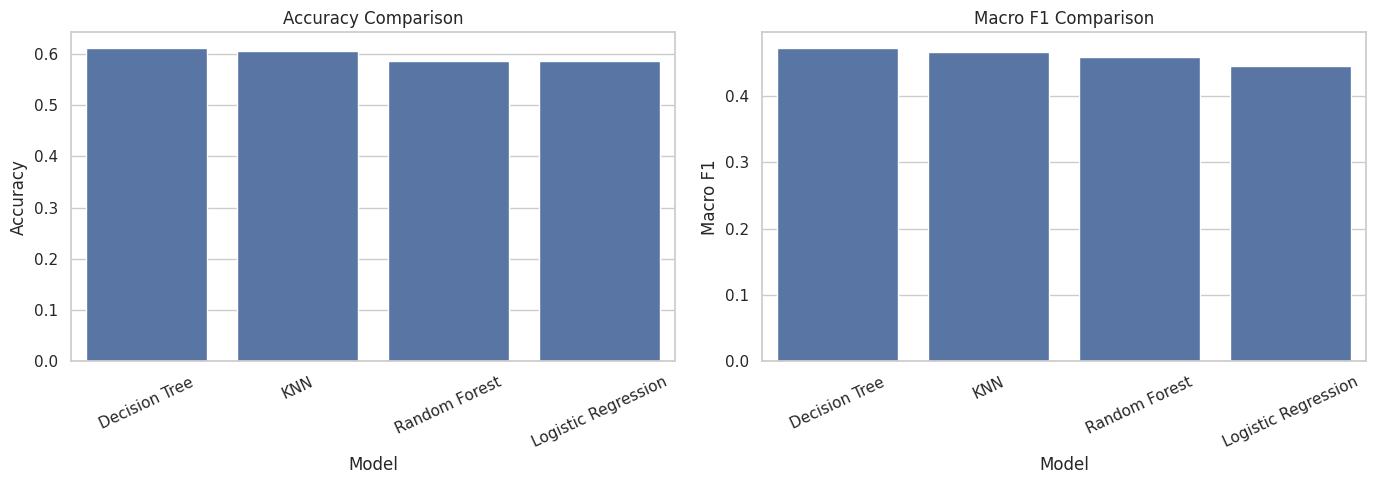

In [ ]:
# Compare model accuracy and macro F1
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy', ax=axes[0])
axes[0].set_title('Accuracy Comparison')
axes[0].tick_params(axis='x', rotation=25)
sns.barplot(data=results_df, x='Model', y='Macro F1', ax=axes[1])
axes[1].set_title('Macro F1 Comparison')
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

Best baseline by Macro F1: Decision Tree


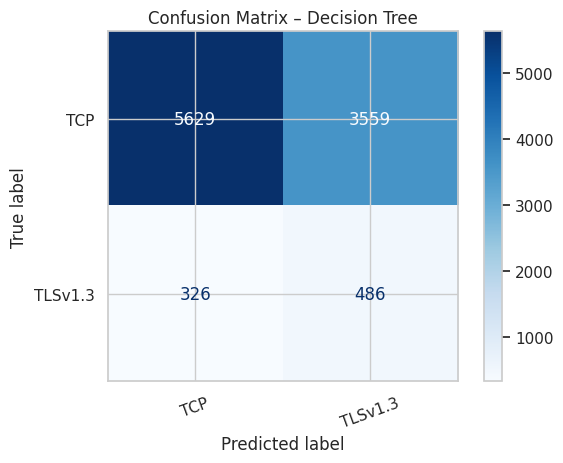

In [ ]:
best_baseline_name = results_df.iloc[0]['Model']
best_baseline_model = models[best_baseline_name]
print('Best baseline by Macro F1:', best_baseline_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_by_model[best_baseline_name],
    xticks_rotation=20,
    cmap='Blues'
)
plt.title(f'Confusion Matrix – {best_baseline_name}')
plt.tight_layout()
plt.show()

In [ ]:
# Build a smaller chronological tuning subset to keep the search practical.
TUNE_PER_CLASS = 3_000
tune_parts = []
for label, group in train_full.groupby(TARGET, observed=True):
    tune_parts.append(
        group.sample(n=min(TUNE_PER_CLASS, len(group)), random_state=RANDOM_STATE)
    )
tune_df = pd.concat(tune_parts).sort_values('Time', kind='mergesort')
X_tune = tune_df[FEATURES]
y_tune = tune_df[TARGET].astype(str)

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        class_weight='balanced_subsample',
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

param_distributions = {
    'model__n_estimators': [50, 80, 100],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

cv = TimeSeriesSplit(n_splits=3)
search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=3,
    scoring='f1_macro',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)
search.fit(X_tune, y_tune)

print('Best parameters:', search.best_params_)
print('Best time-series CV macro F1:', search.best_score_)
optimized_model = search.best_estimator_

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': None}
Best time-series CV macro F1: 0.5936633547644841


Optimized Random Forest results:
              precision    recall  f1-score   support

         TCP       0.95      0.56      0.70      9188
     TLSv1.3       0.11      0.64      0.19       812

    accuracy                           0.56     10000
   macro avg       0.53      0.60      0.45     10000
weighted avg       0.88      0.56      0.66     10000

{'Accuracy': 0.5632, 'Macro Precision': 0.5300539466143801, 'Macro Recall': 0.6000700206523394, 'Macro F1': 0.44686878344715325}


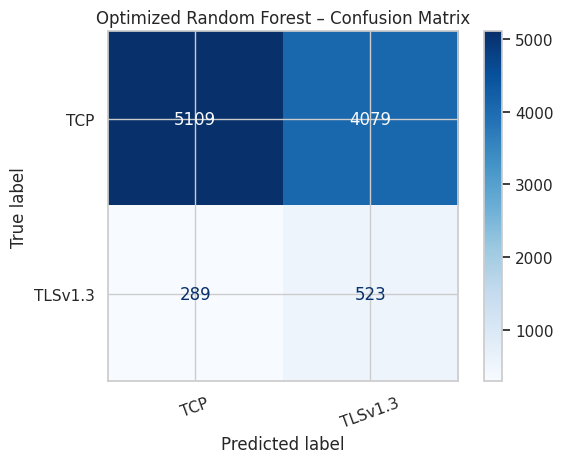

In [ ]:
optimized_predictions = optimized_model.predict(X_test)
print('Optimized Random Forest results:')
print(classification_report(y_test, optimized_predictions, zero_division=0))

optimized_metrics = {
    'Accuracy': accuracy_score(y_test, optimized_predictions),
    'Macro Precision': precision_score(y_test, optimized_predictions, average='macro', zero_division=0),
    'Macro Recall': recall_score(y_test, optimized_predictions, average='macro', zero_division=0),
    'Macro F1': f1_score(y_test, optimized_predictions, average='macro', zero_division=0)
}
print(optimized_metrics)

ConfusionMatrixDisplay.from_predictions(
    y_test, optimized_predictions, xticks_rotation=20, cmap='Blues'
)
plt.title('Optimized Random Forest – Confusion Matrix')
plt.tight_layout()
plt.show()

,Feature,Importance
0,Length,0.445798
1,delta_ms,0.345222
3,prev5_mean_length,0.187394
2,prev_length,0.021586


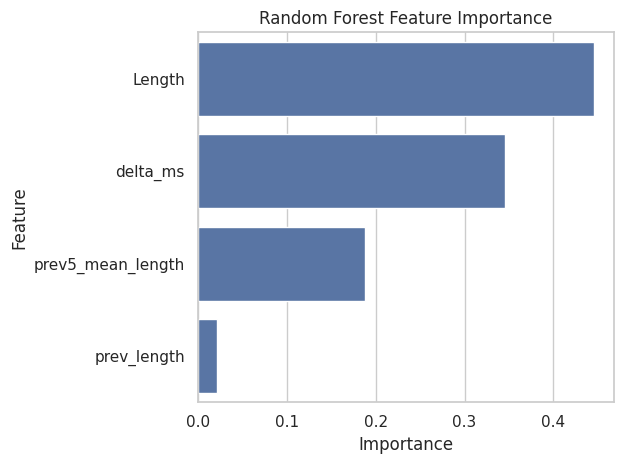

In [ ]:
# Feature importance for the optimized Random Forest
rf_model = optimized_model.named_steps['model']
importance_df = pd.DataFrame({
    'Feature': FEATURES,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

display(importance_df)
sns.barplot(data=importance_df, x='Importance', y='Feature')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

In [ ]:
# Set this path when you have a separate Netflix capture.
EXTERNAL_ZIP_PATH = '/content/drive/MyDrive/Netflix_2.zip'

if os.path.exists(EXTERNAL_ZIP_PATH):
    with zipfile.ZipFile(EXTERNAL_ZIP_PATH, 'r') as zf:
        external_csvs = [name for name in zf.namelist() if name.lower().endswith('.csv')]
        if not external_csvs:
            raise ValueError('No CSV found in the external ZIP.')
        with zf.open(external_csvs[0]) as csv_file:
            external_raw = pd.read_csv(
                csv_file,
                usecols=['Time', 'Protocol', 'Length'],
                dtype={'Protocol': 'category'},
                low_memory=False
            )

    external_features = make_features(external_raw)
    external_features = external_features[
        external_features[TARGET].astype(str).isin(
            optimized_model.named_steps['model'].classes_
        )
    ].copy()

    X_external = external_features[FEATURES]
    y_external = external_features[TARGET].astype(str)
    external_predictions = optimized_model.predict(X_external)

    print('Independent capture shape:', external_features.shape)
    print(classification_report(y_external, external_predictions, zero_division=0))
else:
    print('Independent test skipped: upload Netflix_2.zip and update EXTERNAL_ZIP_PATH.')

Independent test skipped: upload Netflix_2.zip and update EXTERNAL_ZIP_PATH.


In [ ]:
OUTPUT_DIR = '/content/drive/MyDrive/Netflix_ML_Outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(optimized_model, os.path.join(OUTPUT_DIR, 'netflix_protocol_model.pkl'))
results_df.to_csv(os.path.join(OUTPUT_DIR, 'model_comparison.csv'), index=False)
importance_df.to_csv(os.path.join(OUTPUT_DIR, 'feature_importance.csv'), index=False)
pd.DataFrame([optimized_metrics]).to_csv(
    os.path.join(OUTPUT_DIR, 'optimized_model_metrics.csv'), index=False
)

print('Saved outputs to:', OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

Saved outputs to: /content/drive/MyDrive/Netflix_ML_Outputs
['netflix_protocol_model.pkl', 'model_comparison.csv', 'feature_importance.csv', 'optimized_model_metrics.csv']


In [ ]:
print('FINAL PROJECT SUMMARY')
print('----------------------')
print('Dataset: Netflix packet-capture data')
print('Target column:', TARGET)
print('Protocol classes:', sorted(df_ml[TARGET].astype(str).unique()))
print('Feature columns:', FEATURES)
print('Best baseline model:', best_baseline_name)
print('Optimized model: Random Forest')
print('Optimized holdout metrics:')
for metric, value in optimized_metrics.items():
    print(f'{metric}: {value:.4f}')

FINAL PROJECT SUMMARY
----------------------
Dataset: Netflix packet-capture data
Target column: Protocol
Protocol classes: ['TCP', 'TLSv1.3']
Feature columns: ['Length', 'delta_ms', 'prev_length', 'prev5_mean_length']
Best baseline model: Decision Tree
Optimized model: Random Forest
Optimized holdout metrics:
Accuracy: 0.5632
Macro Precision: 0.5301
Macro Recall: 0.6001
Macro F1: 0.4469


In [ ]:
from sklearn.metrics import classification_report

predictions = optimized_model.predict(X_test)

print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

              precision    recall  f1-score   support

         TCP       0.95      0.56      0.70      9188
     TLSv1.3       0.11      0.64      0.19       812

    accuracy                           0.56     10000
   macro avg       0.53      0.60      0.45     10000
weighted avg       0.88      0.56      0.66     10000



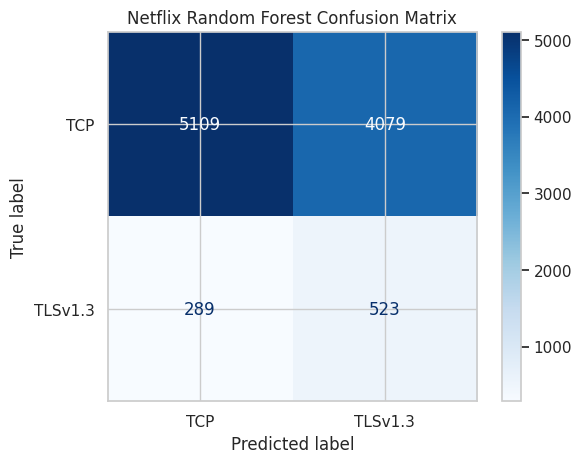

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    cmap='Blues'
)

plt.title("Netflix Random Forest Confusion Matrix")
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Fixed: Changed train_df to train_sample which is defined in your environment
majority_class = (
    train_sample['Protocol'].astype(str).mode()[0]
)

dummy_predictions = np.full(
    len(y_test),
    majority_class
)

print("Majority baseline accuracy:",
      accuracy_score(y_test, dummy_predictions))

print("Majority baseline F1:",
      f1_score(y_test, dummy_predictions,
               average='macro'))

print("Random Forest accuracy:",
      accuracy_score(y_test, predictions))

print("Random Forest F1:",
      f1_score(y_test, predictions,
               average='macro'))

Majority baseline accuracy: 0.9188
Majority baseline F1: 0.4788409422555764
Random Forest accuracy: 0.5632
Random Forest F1: 0.44686878344715325


In [ ]:
from sklearn.metrics import f1_score, accuracy_score

for name, model in models.items():

    pred = model.predict(X_test)

    print("\n", name)
    print("Accuracy:",
          accuracy_score(y_test, pred))

    print("Macro F1:",
          f1_score(y_test, pred,
                   average='macro'))

print("\nOptimized Random Forest")

print("Accuracy:",
      accuracy_score(y_test, predictions))

print("Macro F1:",
      f1_score(y_test, predictions,
               average='macro'))


 Logistic Regression
Accuracy: 0.5859
Macro F1: 0.44421776361361476

 KNN
Accuracy: 0.6063
Macro F1: 0.46620474734475503

 Decision Tree
Accuracy: 0.6115
Macro F1: 0.47178467479699504

 Random Forest
Accuracy: 0.5859
Macro F1: 0.45791418390119276

Optimized Random Forest
Accuracy: 0.5632
Macro F1: 0.44686878344715325


In [ ]:
sample = pd.read_csv(
    DATA_PATH,
    nrows=20
)

display(
    sample[
        ['Time', 'Source', 'Destination',
         'Protocol', 'Length', 'Info']
    ]
)

,Time,Source,Destination,Protocol,Length,Info
0,2022-06-17 23:48:34.871426,192.0.0.2,10.215.173.2,TCP,60,43968 > 853 [SYN] Seq=0 Win=65535 Len=0 MSS=...
1,2022-06-17 23:48:34.953834,10.215.173.1,45.57.41.1,TCP,60,33420 > 443 [SYN] Seq=0 Win=65535 Len=0 MSS=...
2,2022-06-17 23:48:35.035546,45.57.41.1,10.215.173.1,TCP,48,"443 > 33420 [SYN, ACK] Seq=0 Ack=1 Win=1024 ..."
3,2022-06-17 23:48:35.035900,10.215.173.1,45.57.41.1,TCP,40,33420 > 443 [ACK] Seq=1 Ack=1 Win=88064 Len=0
4,2022-06-17 23:48:35.037489,10.215.173.1,45.57.41.1,TCP,552,33420 > 443 [ACK] Seq=1 Ack=1 Win=88064 Len=...
5,2022-06-17 23:48:35.037704,45.57.41.1,10.215.173.1,TCP,40,443 > 33420 [ACK] Seq=1 Ack=513 Win=1047552 ...
6,2022-06-17 23:48:35.037820,10.215.173.1,45.57.41.1,TLSv1.3,45,Client Hello
7,2022-06-17 23:48:35.038033,45.57.41.1,10.215.173.1,TCP,40,443 > 33420 [ACK] Seq=1 Ack=518 Win=1047552 ...
8,2022-06-17 23:48:35.118601,45.57.41.1,10.215.173.1,TLSv1.3,426,"Server Hello, Change Cipher Spec, Application ..."
9,2022-06-17 23:48:35.118990,10.215.173.1,45.57.41.1,TCP,40,33420 > 443 [ACK] Seq=518 Ack=387 Win=89088 ...


In [ ]:
import pandas as pd
import numpy as np

raw_df = pd.read_csv(
    DATA_PATH,
    usecols=[
        'Time', 'Source', 'Destination',
        'Protocol', 'Length', 'Info'
    ],
    low_memory=False
)

info = raw_df['Info'].fillna('')

# Extract source and destination ports
ports = info.str.extract(
    r'^\s*(\d+)\s*>\s*(\d+)'
)

raw_df['Source_Port'] = pd.to_numeric(
    ports[0], errors='coerce'
)

raw_df['Destination_Port'] = pd.to_numeric(
    ports[1], errors='coerce'
)

# Extract TCP flags
flags = info.str.extract(
    r'\[([^\]]+)\]'
)[0].fillna('')

raw_df['SYN'] = flags.str.contains(
    r'\bSYN\b'
).astype(int)

raw_df['ACK'] = flags.str.contains(
    r'\bACK\b'
).astype(int)

raw_df['FIN'] = flags.str.contains(
    r'\bFIN\b'
).astype(int)

raw_df['RST'] = flags.str.contains(
    r'\bRST\b'
).astype(int)

raw_df['PSH'] = flags.str.contains(
    r'\bPSH\b'
).astype(int)

display(
    raw_df[
        ['Protocol', 'Length',
         'Source_Port', 'Destination_Port',
         'SYN', 'ACK', 'FIN', 'RST', 'PSH']
    ].head(20)
)

,Protocol,Length,Source_Port,Destination_Port,SYN,ACK,FIN,RST,PSH
0,TCP,60,43968.0,853.0,1,0,0,0,0
1,TCP,60,33420.0,443.0,1,0,0,0,0
2,TCP,48,443.0,33420.0,1,1,0,0,0
3,TCP,40,33420.0,443.0,0,1,0,0,0
4,TCP,552,33420.0,443.0,0,1,0,0,0
5,TCP,40,443.0,33420.0,0,1,0,0,0
6,TLSv1.3,45,NaN,NaN,0,0,0,0,0
7,TCP,40,443.0,33420.0,0,1,0,0,0
8,TLSv1.3,426,NaN,NaN,0,0,0,0,0
9,TCP,40,33420.0,443.0,0,1,0,0,0


In [ ]:
diagnostics = raw_df.groupby('Protocol').agg(
    Total_Packets=('Protocol', 'size'),

    Source_Port_Available=(
        'Source_Port',
        lambda x: x.notna().mean() * 100
    ),

    Destination_Port_Available=(
        'Destination_Port',
        lambda x: x.notna().mean() * 100
    ),

    Average_Length=('Length', 'mean'),

    SYN_Count=('SYN', 'sum'),

    ACK_Count=('ACK', 'sum')
)

display(diagnostics)

,Total_Packets,Source_Port_Available,Destination_Port_Available,Average_Length,SYN_Count,ACK_Count
Protocol,,,,,,
TCP,3942556,99.999822,99.999822,1153.283778,1647,3941591
TLSv1.3,348222,0.000000,0.000000,1368.847945,0,0


In [ ]:
import os
from pathlib import Path
import zipfile

search_locations = [
    Path('/content'),
    Path('/content/drive/MyDrive')
]

capture_extensions = [
    '.pcap',
    '.pcapng',
    '.cap'
]

found_files = set()

# Search for capture files
for location in search_locations:

    if not location.exists():
        continue

    for path in location.rglob('*'):

        if path.is_file():

            name = path.name.lower()

            if any(
                name.endswith(ext) or name.endswith(ext + '.gz')
                for ext in capture_extensions
            ):
                found_files.add(str(path))

print("CAPTURE FILES FOUND:")

if found_files:
    for file in sorted(found_files):
        print(file)
else:
    print("No PCAP/PCAPNG files found.")

CAPTURE FILES FOUND:
No PCAP/PCAPNG files found.


In [ ]:
for location in search_locations:

    for path in location.rglob('*.zip'):

        try:
            with zipfile.ZipFile(path) as archive:

                for name in archive.namelist():

                    if name.lower().endswith(
                        ('.pcap', '.pcapng', '.cap')
                    ):
                        print("Capture found inside ZIP:")
                        print("Archive:", path)
                        print("File:", name)

        except (zipfile.BadZipFile, PermissionError):
            continue

In [ ]:
import os
import zipfile
from pathlib import Path

# Search locations
SEARCH_PATH = Path('/content')

# Capture file extensions
extensions = ('.pcap', '.pcapng', '.cap')

capture_files = []
zip_files = []

print("Searching for original network capture files...\n")

# Search Colab and mounted Google Drive
for root, dirs, files in os.walk(SEARCH_PATH):

    dirs[:] = [
        d for d in dirs
        if d not in ['.config', '.cache', '__pycache__']
    ]

    for filename in files:

        filepath = Path(root) / filename
        lower_name = filename.lower()

        # Direct capture files
        if lower_name.endswith(extensions):
            capture_files.append(str(filepath))

        # Capture files inside ZIP archives
        elif lower_name.endswith('.zip'):
            zip_files.append(filepath)

# Check ZIP contents
zip_captures = []

for zip_path in zip_files:
    try:
        with zipfile.ZipFile(zip_path, 'r') as archive:

            for name in archive.namelist():
                if name.lower().endswith(extensions):
                    zip_captures.append(
                        (str(zip_path), name)
                    )

    except (zipfile.BadZipFile, PermissionError):
        continue

# Display results
print("========== SEARCH RESULTS ==========")

if capture_files:
    print("\nPCAP FILES FOUND:")
    for file in capture_files:
        print(file)
else:
    print("\nNo direct PCAP files found.")

if zip_captures:
    print("\nPCAP FILES INSIDE ZIP:")
    for archive, filename in zip_captures:
        print("ZIP:", archive)
        print("FILE:", filename)
else:
    print("\nNo PCAP files found inside ZIP archives.")

if not capture_files and not zip_captures:
    print("\nNo original capture files found.")
    print("Your CSV dataset is still available for analysis.")

print("\n========== SEARCH COMPLETED ==========")

Searching for original network capture files...

========== SEARCH RESULTS ==========

No direct PCAP files found.

No PCAP files found inside ZIP archives.

No original capture files found.
Your CSV dataset is still available for analysis.

========== SEARCH COMPLETED ==========


In [ ]:
# IMPROVED FEATURE ENGINEERING USING CSV DATA

import pandas as pd
import numpy as np

data = raw_df[
    ['Time', 'Source', 'Destination', 'Protocol', 'Length']
].copy()

data['Time'] = pd.to_datetime(
    data['Time'], errors='coerce'
)

data = data.dropna(
    subset=['Time', 'Source', 'Destination',
            'Protocol', 'Length']
)

# Sort packets chronologically
data = data.sort_values(
    'Time', kind='mergesort'
).reset_index(drop=True)

# Create IP codes
ip_index = pd.Index(pd.unique(pd.concat([
    data['Source'],
    data['Destination']
], ignore_index=True)))

src = ip_index.get_indexer(data['Source'])
dst = ip_index.get_indexer(data['Destination'])

# Create bidirectional IP-pair identifier
low = np.minimum(src, dst)
high = np.maximum(src, dst)

data['pair_id'] = low * len(ip_index) + high

# Packet direction
data['direction'] = (src == low).astype('int8')

# Group packets by IP pair
group = data.groupby('pair_id', sort=False)

# Time difference between packets of the same IP pair
data['pair_delta_ms'] = (
    group['Time'].diff().dt.total_seconds() * 1000
)

# Previous packet length
data['pair_prev_length'] = group['Length'].shift(1)

# Previous five packet average length
previous = group['Length'].shift(1)

data['pair_prev5_mean_length'] = (
    previous.groupby(data['pair_id'], sort=False)
    .rolling(5, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)

# Final feature dataset
model_df = data[
    [
        'Time', 'Protocol', 'Length',
        'direction', 'pair_delta_ms',
        'pair_prev_length',
        'pair_prev5_mean_length'
    ]
].copy()

print("Feature engineering completed!")
print("Dataset shape:", model_df.shape)

display(model_df.head())

Feature engineering completed!
Dataset shape: (4290778, 7)


,Time,Protocol,Length,direction,pair_delta_ms,pair_prev_length,pair_prev5_mean_length
0,2022-06-17 23:48:34.871426,TCP,60,1,NaN,NaN,NaN
1,2022-06-17 23:48:34.953834,TCP,60,1,NaN,NaN,NaN
2,2022-06-17 23:48:35.035546,TCP,48,0,81.712,60.0,60.000000
3,2022-06-17 23:48:35.035900,TCP,40,1,0.354,48.0,54.000000
4,2022-06-17 23:48:35.037489,TCP,552,1,1.589,40.0,49.333333


In [ ]:
print(model_df.shape)
print(model_df.isnull().sum())
print(model_df['Protocol'].value_counts())

(4290778, 7)
Time                       0
Protocol                   0
Length                     0
direction                  0
pair_delta_ms             38
pair_prev_length          38
pair_prev5_mean_length    38
dtype: int64
Protocol
TCP        3942556
TLSv1.3     348222
Name: count, dtype: int64


In [ ]:
# STEP 1: CHRONOLOGICAL TRAIN-TEST SPLIT

model_df = model_df.sort_values('Time').reset_index(drop=True)

split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining class distribution:")
print(train_df['Protocol'].value_counts())

print("\nTesting class distribution:")
print(test_df['Protocol'].value_counts())

Training records: 3432622
Testing records: 858156

Training class distribution:
Protocol
TCP        3154054
TLSv1.3     278568
Name: count, dtype: int64

Testing class distribution:
Protocol
TCP        788502
TLSv1.3     69654
Name: count, dtype: int64


In [ ]:
# STEP 2: SAMPLE DATA

train_sample = train_df.sample(
    n=min(50000, len(train_df)),
    random_state=42
)

test_sample = test_df.sample(
    n=min(10000, len(test_df)),
    random_state=42
)

features = [
    'Length',
    'direction',
    'pair_delta_ms',
    'pair_prev_length',
    'pair_prev5_mean_length'
]

X_train = train_sample[features]
y_train = train_sample['Protocol'].astype(str)

X_test = test_sample[features]
y_test = test_sample['Protocol'].astype(str)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (50000, 5)
X_test: (10000, 5)


In [ ]:
# STEP 3: DEFINE MODELS

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {

    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=500,
            class_weight='balanced'
        ))
    ]),

    'KNN': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(
            n_neighbors=7,
            weights='distance',
            algorithm='kd_tree',
            n_jobs=-1
        ))
    ]),

    'Decision Tree': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', DecisionTreeClassifier(
            max_depth=15,
            min_samples_leaf=20,
            class_weight='balanced',
            random_state=42
        ))
    ]),

    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(
            n_estimators=100,
            max_depth=18,
            min_samples_leaf=5,
            class_weight='balanced_subsample',
            random_state=42,
            n_jobs=-1
        ))
    ])
}

In [ ]:
for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    print(name, "completed!\n")

Training: Logistic Regression
Logistic Regression completed!

Training: KNN
KNN completed!

Training: Decision Tree
Decision Tree completed!

Training: Random Forest
Random Forest completed!



In [ ]:
# STEP 5: MODEL EVALUATION

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models.items():

    predictions = model.predict(X_test)

    results.append({

        'Model': name,

        'Accuracy': accuracy_score(
            y_test, predictions
        ),

        'Precision': precision_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),

        'Recall': recall_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),

        'F1 Score': f1_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        'F1 Score',
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,KNN,0.9257,0.798437,0.568152,0.597882
3,Random Forest,0.5436,0.533037,0.612147,0.438524
0,Logistic Regression,0.5695,0.514055,0.546902,0.436158
2,Decision Tree,0.4873,0.533132,0.611223,0.408048


In [ ]:
from sklearn.metrics import classification_report

baseline_class = y_train.mode()[0]

baseline_predictions = np.full(
    len(y_test),
    baseline_class
)

print("Majority baseline accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Majority baseline macro F1:",
      f1_score(
          y_test,
          baseline_predictions,
          average='macro',
          zero_division=0
      ))

Majority baseline accuracy: 0.92
Majority baseline macro F1: 0.4791666666666667


In [ ]:
# SELECT BEST MODEL USING MACRO F1

best_name = results_df.loc[
    results_df['F1 Score'].idxmax(),
    'Model'
]

best_model = models[best_name]

print("Best Model:", best_name)

# Predictions
best_predictions = best_model.predict(X_test)

Best Model: KNN


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

              precision    recall  f1-score   support

         TCP       0.93      0.99      0.96      9200
     TLSv1.3       0.67      0.14      0.23       800

    accuracy                           0.93     10000
   macro avg       0.80      0.57      0.60     10000
weighted avg       0.91      0.93      0.90     10000



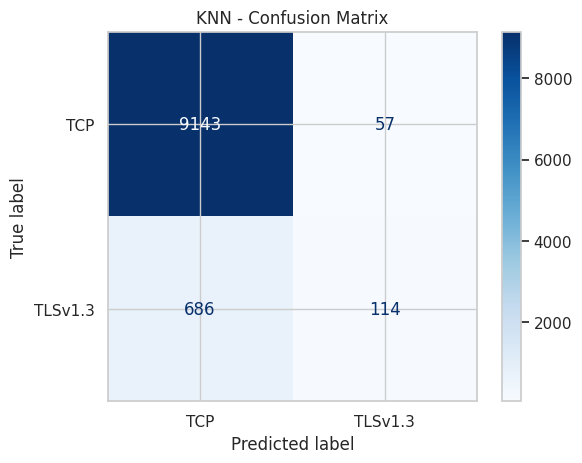

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    cmap='Blues'
)

plt.title(f'{best_name} - Confusion Matrix')
plt.show()

In [ ]:
import joblib

joblib.dump(
    best_model,
    'Netflix_Best_Model_KNN.pkl'
)

print("Best model saved successfully!")

Best model saved successfully!


In [ ]:
!pip install -q imbalanced-learn

from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

In [ ]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training:", X_fit.shape)
print("Validation:", X_val.shape)

print("\nOriginal training distribution:")
print(y_fit.value_counts())

Training: (40000, 5)
Validation: (10000, 5)

Original training distribution:
Protocol
TCP        36792
TLSv1.3     3208
Name: count, dtype: int64


In [ ]:
from imblearn.pipeline import Pipeline as ImblearnPipeline

results = []
trained_models = {}

for k in [5, 7, 11, 15, 21]:

    # Use imblearn's Pipeline to natively handle RandomOverSampler
    model = ImblearnPipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('sampler', RandomOverSampler(random_state=42)),
        ('knn', KNeighborsClassifier(
            n_neighbors=k,
            weights='distance',
            n_jobs=-1
        ))
    ])

    model.fit(X_fit, y_fit)

    predictions = model.predict(X_val)

    score = f1_score(
        y_val,
        predictions,
        average='macro',
        zero_division=0
    )

    results.append({
        'K': k,
        'Macro F1': score
    })

    trained_models[k] = model

results_df = pd.DataFrame(results)

display(results_df.sort_values(
    'Macro F1',
    ascending=False
))

,K,Macro F1
1,7,0.583689
0,5,0.583142
2,11,0.575862
3,15,0.570903
4,21,0.566440


In [ ]:
best_k = int(
    results_df.loc[
        results_df['Macro F1'].idxmax(),
        'K'
    ]
)

best_model = trained_models[best_k]

print("Best K:", best_k)

val_predictions = best_model.predict(X_val)

print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))

Best K: 7
              precision    recall  f1-score   support

         TCP       0.93      0.97      0.95      9198
     TLSv1.3       0.33      0.16      0.22       802

    accuracy                           0.91     10000
   macro avg       0.63      0.57      0.58     10000
weighted avg       0.88      0.91      0.89     10000



In [ ]:
# Retrain using all available training samples
best_model.fit(X_train, y_train)

final_predictions = best_model.predict(X_test)

print("FINAL KNN RESULTS")

print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

FINAL KNN RESULTS
              precision    recall  f1-score   support

         TCP       0.93      0.97      0.95      9200
     TLSv1.3       0.37      0.18      0.25       800

    accuracy                           0.91     10000
   macro avg       0.65      0.58      0.60     10000
weighted avg       0.89      0.91      0.90     10000



In [ ]:
import joblib

joblib.dump(
    best_model,
    '/content/Netflix_Final_KNN_Model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


       NETFLIX NETWORK TRAFFIC CLASSIFICATION
                FINAL PROJECT REPORT

PROJECT INFORMATION
-------------------------------------------------------
Dataset          : Netflix Network Traffic
Target Variable  : Protocol
Protocol Classes : ['TCP', 'TLSv1.3']
Training Records : 50000
Testing Records  : 10000
Features Used    : 5

SELECTED MACHINE LEARNING MODEL
-------------------------------------------------------
Algorithm        : K-Nearest Neighbors (KNN)
Best K Value     : 7

OVERALL PERFORMANCE
-------------------------------------------------------
Accuracy         : 91.01%
Macro Precision  : 65.30%
Macro Recall     : 57.85%
Macro F1-Score   : 0.5993

DETAILED CLASSIFICATION REPORT
-------------------------------------------------------
              precision    recall  f1-score   support

         TCP     0.9320    0.9733    0.9522      9200
     TLSv1.3     0.3740    0.1837    0.2464       800

    accuracy                         0.9101     10000
   macro avg     0

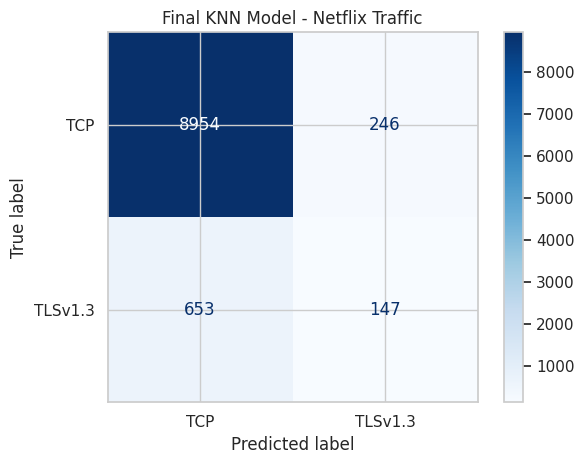


PROJECT EVALUATION COMPLETED
Model saved successfully!
Classification report exported successfully!


In [ ]:
# ==========================================
#       FINAL MACHINE LEARNING REPORT
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Generate final predictions
final_predictions = best_model.predict(X_test)

# Calculate performance metrics
accuracy = accuracy_score(y_test, final_predictions)

precision = precision_score(
    y_test, final_predictions,
    average='macro', zero_division=0
)

recall = recall_score(
    y_test, final_predictions,
    average='macro', zero_division=0
)

f1 = f1_score(
    y_test, final_predictions,
    average='macro', zero_division=0
)

# Print final report
print("=" * 55)
print("       NETFLIX NETWORK TRAFFIC CLASSIFICATION")
print("                FINAL PROJECT REPORT")
print("=" * 55)

print("\nPROJECT INFORMATION")
print("-" * 55)
print("Dataset          : Netflix Network Traffic")
print("Target Variable  : Protocol")
print("Protocol Classes :", list(np.unique(y_test)))
print("Training Records :", len(X_train))
print("Testing Records  :", len(X_test))
print("Features Used    :", len(features))

print("\nSELECTED MACHINE LEARNING MODEL")
print("-" * 55)
print("Algorithm        : K-Nearest Neighbors (KNN)")
print("Best K Value     :", best_k)

print("\nOVERALL PERFORMANCE")
print("-" * 55)
print(f"Accuracy         : {accuracy * 100:.2f}%")
print(f"Macro Precision  : {precision * 100:.2f}%")
print(f"Macro Recall     : {recall * 100:.2f}%")
print(f"Macro F1-Score   : {f1:.4f}")

print("\nDETAILED CLASSIFICATION REPORT")
print("-" * 55)

print(classification_report(
    y_test,
    final_predictions,
    zero_division=0,
    digits=4
))

print("\nCONFUSION MATRIX")
print("-" * 55)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    cmap='Blues',
    values_format='d'
)

plt.title("Final KNN Model - Netflix Traffic")
plt.tight_layout()
plt.show()

# Save trained model and report
joblib.dump(
    best_model,
    '/content/Netflix_Final_KNN_Model.pkl'
)

report = classification_report(
    y_test,
    final_predictions,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    '/content/Netflix_Final_Classification_Report.csv'
)

print("\n" + "=" * 55)
print("PROJECT EVALUATION COMPLETED")
print("Model saved successfully!")
print("Classification report exported successfully!")
print("=" * 55)

In [7]:
import os

DATA_PATH = '/content/Netflix_1.csv'

print("Dataset exists:", os.path.exists(DATA_PATH))

Dataset exists: False


In [13]:
import os
import pandas as pd

DATA_PATH = '/content/Netflix_1.csv'

# Load dataset if raw_df doesn't exist
if 'raw_df' not in globals():

    if os.path.exists(DATA_PATH):
        raw_df = pd.read_csv(DATA_PATH, low_memory=False)
        print("Dataset loaded successfully!")

    else:
        raise FileNotFoundError(
            "Netflix_1.csv not found. Upload the CSV first."
        )

# Check duplicate records
duplicate_count = raw_df.duplicated().sum()

print("Total duplicate records:", duplicate_count)
print("Dataset shape:", raw_df.shape)
print("Duplicate check completed!")

Dataset loaded successfully!
Total duplicate records: 0
Dataset shape: (4290778, 7)
Duplicate check completed!


In [14]:
# STEP 2: TIME FEATURE EXTRACTION

time_features_df = raw_df[
    ['Time', 'Protocol', 'Length']
].copy()

time_features_df['Time'] = pd.to_datetime(
    time_features_df['Time'],
    errors='coerce'
)

time_features_df['Hour'] = time_features_df['Time'].dt.hour
time_features_df['Minute'] = time_features_df['Time'].dt.minute
time_features_df['Second'] = time_features_df['Time'].dt.second

print("Time features extracted successfully!")

display(
    time_features_df[
        ['Time', 'Hour', 'Minute', 'Second']
    ].head()
)

Time features extracted successfully!


,Time,Hour,Minute,Second
0,2022-06-17 23:48:34.871426,23,48,34
1,2022-06-17 23:48:34.953834,23,48,34
2,2022-06-17 23:48:35.035546,23,48,35
3,2022-06-17 23:48:35.035900,23,48,35
4,2022-06-17 23:48:35.037489,23,48,35


Feature engineering completed!
Dataset shape: (4290778, 7)


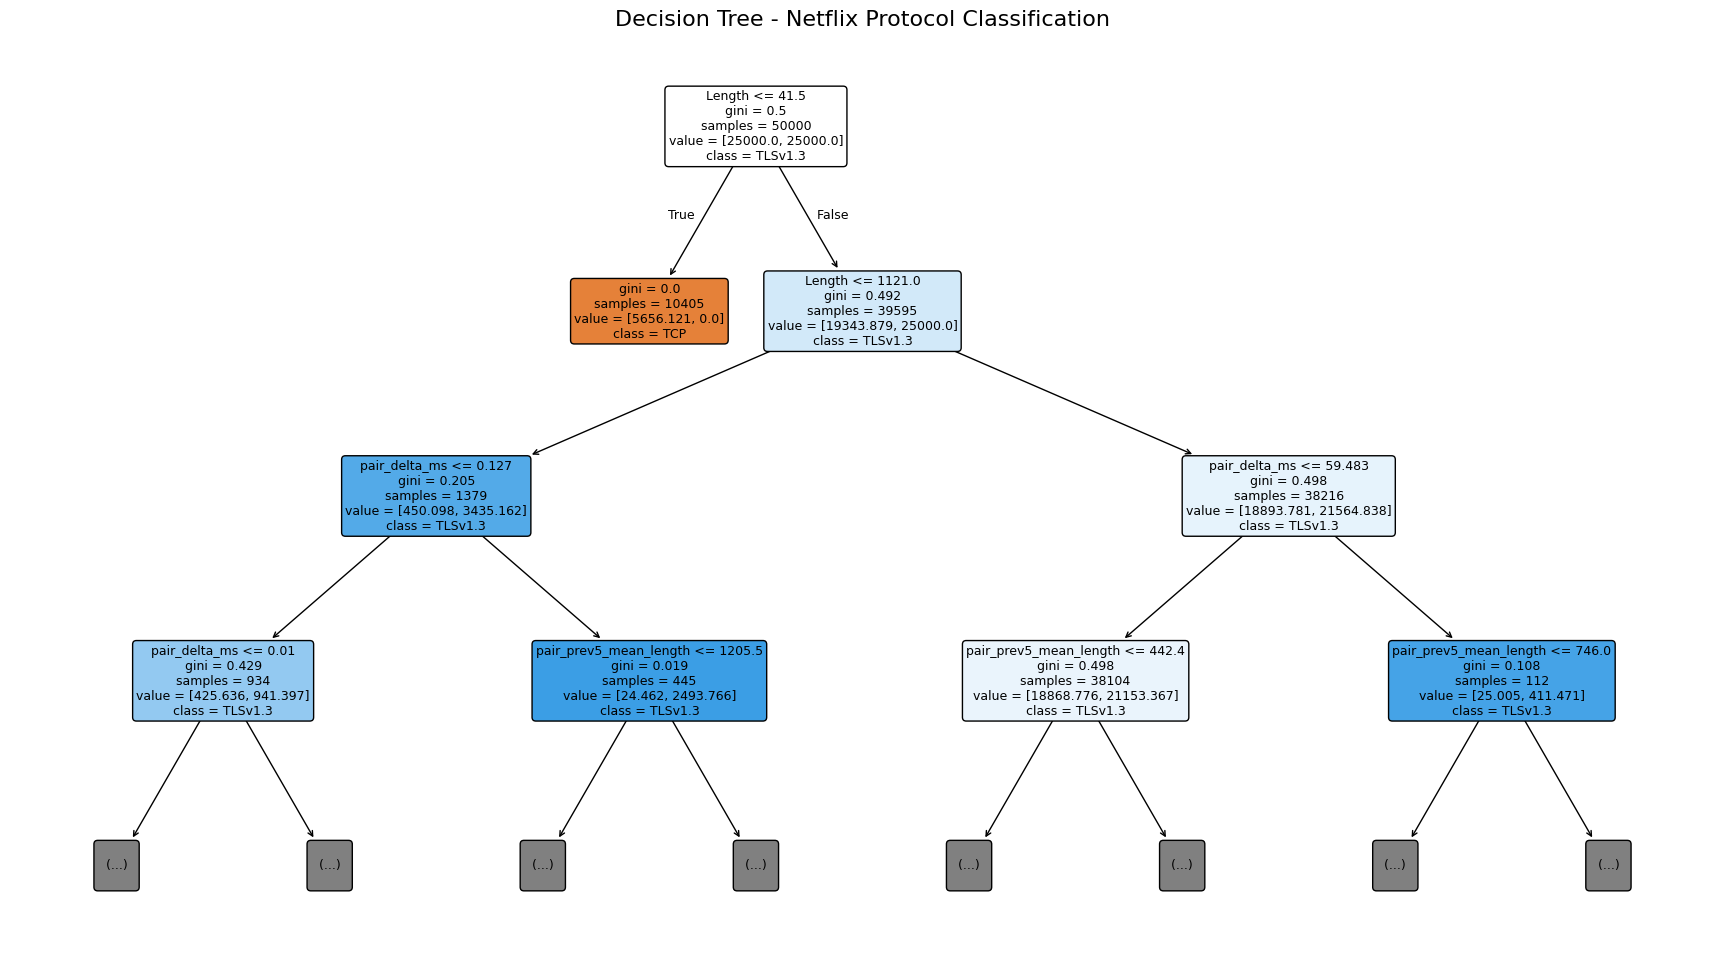

Decision Tree visualization completed!


In [17]:
# ==========================================
# DECISION TREE VISUALIZATION
# ==========================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# 1. Load dataset if required
if 'raw_df' not in globals():

    DATA_PATH = '/content/Netflix_1.csv'

    if not os.path.exists(DATA_PATH):
        raise FileNotFoundError("Netflix_1.csv not found!")

    raw_df = pd.read_csv(DATA_PATH, low_memory=False)

# 2. Prepare dataset
data = raw_df[
    ['Time', 'Source', 'Destination', 'Protocol', 'Length']
].copy()

data['Time'] = pd.to_datetime(
    data['Time'], errors='coerce'
)

data['Length'] = pd.to_numeric(
    data['Length'], errors='coerce'
)

data.dropna(
    subset=['Time', 'Source', 'Destination',
            'Protocol', 'Length'],
    inplace=True
)

data.sort_values('Time', inplace=True)
data.reset_index(drop=True, inplace=True)

# 3. Create IP pair features
all_ips = pd.concat(
    [data['Source'], data['Destination']],
    ignore_index=True
)

ip_codes, unique_ips = pd.factorize(all_ips)

src = ip_codes[:len(data)]
dst = ip_codes[len(data):]

low = np.minimum(src, dst)
high = np.maximum(src, dst)

data['pair_id'] = low * len(unique_ips) + high

data['direction'] = (src == low).astype('int8')

group = data.groupby('pair_id', sort=False)

data['pair_delta_ms'] = (
    group['Time'].diff().dt.total_seconds() * 1000
)

data['pair_prev_length'] = group['Length'].shift(1)

previous = group['Length'].shift(1)

data['pair_prev5_mean_length'] = (
    previous.groupby(data['pair_id'], sort=False)
    .rolling(5, min_periods=1)
    .mean()
    .reset_index(level=0, drop=True)
)

# 4. Create model dataset
model_df = data[
    [
        'Time', 'Protocol', 'Length', 'direction',
        'pair_delta_ms', 'pair_prev_length',
        'pair_prev5_mean_length'
    ]
].copy()

features = [
    'Length',
    'direction',
    'pair_delta_ms',
    'pair_prev_length',
    'pair_prev5_mean_length'
]

print("Feature engineering completed!")
print("Dataset shape:", model_df.shape)

# 5. Prepare training data
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index]

train_sample = train_df.sample(
    n=min(50000, len(train_df)),
    random_state=42
)

X_tree = train_sample[features]
y_tree = train_sample['Protocol'].astype(str)

# 6. Train Decision Tree
dt_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42
    ))
])

dt_model.fit(X_tree, y_tree)

# 7. Visualize Decision Tree
tree = dt_model.named_steps['model']

plt.figure(figsize=(22, 12))

plot_tree(
    tree,
    feature_names=features,
    class_names=[
        str(x) for x in tree.classes_
    ],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title(
    "Decision Tree - Netflix Protocol Classification",
    fontsize=16
)

plt.show()

print("Decision Tree visualization completed!")

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,Length,0.474650
2,pair_delta_ms,0.214421
4,pair_prev5_mean_length,0.140326
1,direction,0.120495
3,pair_prev_length,0.050108


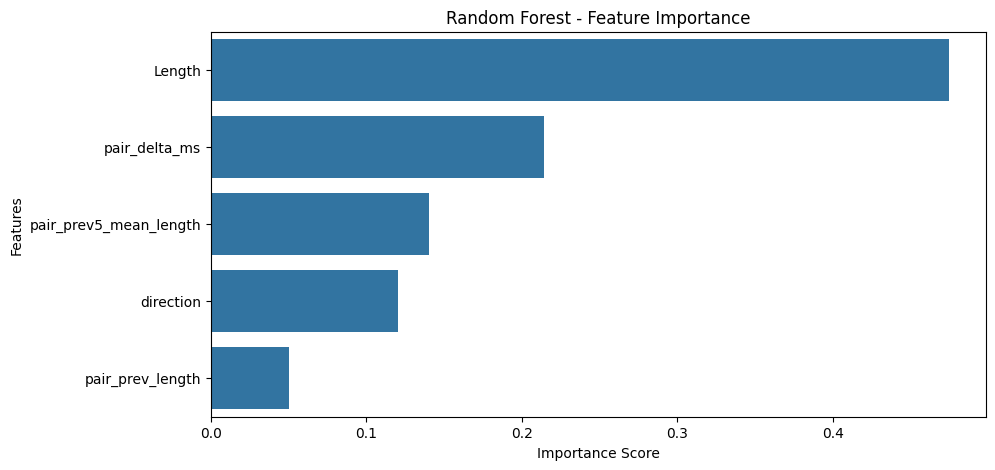

Feature importance analysis completed!


In [18]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Train Random Forest
rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=5,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_tree, y_tree)

# Extract feature importance
importance = rf_model.named_steps[
    'model'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
}).sort_values(
    by='Importance',
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(importance_df)

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

print("Feature importance analysis completed!")

In [19]:
# ==========================================
# STEP 28: PREDICT A NEW NETWORK PACKET
# ==========================================

!pip -q install imbalanced-learn

import pandas as pd
import joblib

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler

# 1. Select features
features = [
    'Length',
    'direction',
    'pair_delta_ms',
    'pair_prev_length',
    'pair_prev5_mean_length'
]

# 2. Prepare chronological training/testing data
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

train_sample = train_df.sample(
    n=min(50000, len(train_df)),
    random_state=42
)

test_sample = test_df.sample(
    n=min(10000, len(test_df)),
    random_state=42
)

X_train = train_sample[features]
y_train = train_sample['Protocol'].astype(str)

X_test = test_sample[features]
y_test = test_sample['Protocol'].astype(str)

# 3. Train final KNN model
best_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('sampler', RandomOverSampler(random_state=42)),
    ('knn', KNeighborsClassifier(
        n_neighbors=7,
        weights='distance',
        n_jobs=-1
    ))
])

best_model.fit(X_train, y_train)

# 4. Select one unseen packet
new_packet = X_test.iloc[[0]].copy()

# 5. Predict protocol
prediction = best_model.predict(new_packet)

actual = y_test.iloc[0]

# 6. Display result
print("=" * 45)
print("       NEW PACKET PREDICTION")
print("=" * 45)

print("\nPacket Information:")
display(new_packet)

print("Predicted Protocol :", prediction[0])
print("Actual Protocol    :", actual)

print("Prediction Status :",
      "Correct" if prediction[0] == actual
      else "Incorrect")

print("=" * 45)

# 7. Save model
joblib.dump(
    best_model,
    '/content/Netflix_Final_KNN_Model.pkl'
)

print("Final KNN model saved successfully!")

       NEW PACKET PREDICTION

Packet Information:


,Length,direction,pair_delta_ms,pair_prev_length,pair_prev5_mean_length
4175031,40,1,0.056,1500.0,1208.0


Predicted Protocol : TCP
Actual Protocol    : TCP
Prediction Status : Correct
Final KNN model saved successfully!


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,Length,0.474650
2,pair_delta_ms,0.214421
4,pair_prev5_mean_length,0.140326
1,direction,0.120495
3,pair_prev_length,0.050108


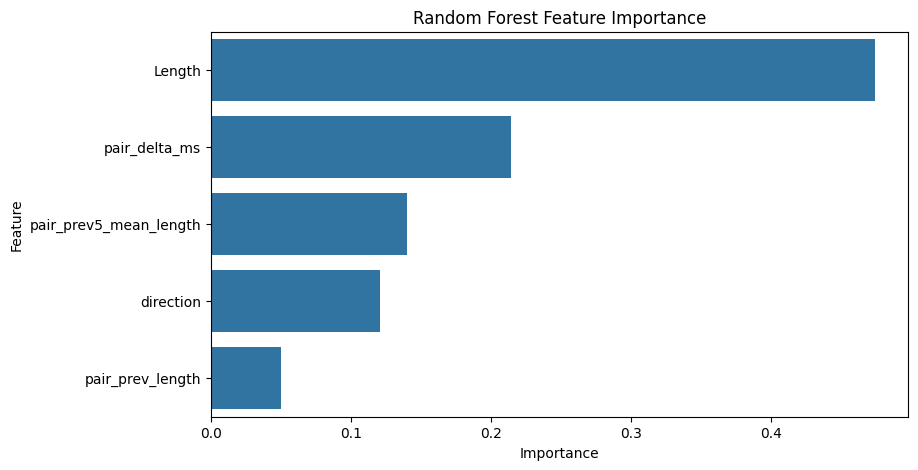


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

         TCP       0.95      0.53      0.68      9200
     TLSv1.3       0.11      0.69      0.20       800

    accuracy                           0.54     10000
   macro avg       0.53      0.61      0.44     10000
weighted avg       0.89      0.54      0.64     10000



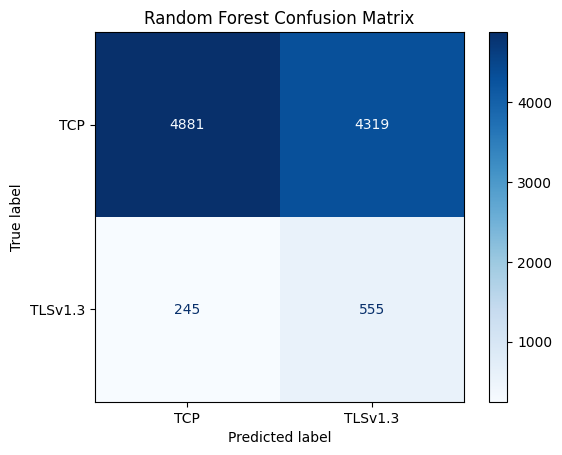


Random Forest evaluation completed!
Model and feature importance saved!


In [20]:
# ==========================================
# FINAL: RANDOM FOREST EVALUATION
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Prepare data
features = [
    'Length',
    'direction',
    'pair_delta_ms',
    'pair_prev_length',
    'pair_prev5_mean_length'
]

model_df = model_df.sort_values('Time').reset_index(drop=True)

split = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split]
test_df = model_df.iloc[split:]

train_sample = train_df.sample(
    n=min(50000, len(train_df)),
    random_state=42
)

test_sample = test_df.sample(
    n=min(10000, len(test_df)),
    random_state=42
)

X_train_rf = train_sample[features]
y_train_rf = train_sample['Protocol'].astype(str)

X_test_rf = test_sample[features]
y_test_rf = test_sample['Protocol'].astype(str)

# Train Random Forest
rf_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=5,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train_rf, y_train_rf)

predictions = rf_model.predict(X_test_rf)

# STEP 26: FEATURE IMPORTANCE
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.named_steps[
        'model'
    ].feature_importances_
}).sort_values('Importance', ascending=False)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)
plt.title("Random Forest Feature Importance")
plt.show()

# STEP 27: CLASSIFICATION REPORT
print("\nRANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test_rf,
    predictions,
    zero_division=0
))

# CONFUSION MATRIX
ConfusionMatrixDisplay.from_predictions(
    y_test_rf,
    predictions,
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.show()

# SAVE RESULTS
joblib.dump(rf_model, '/content/Netflix_Random_Forest.pkl')

importance_df.to_csv(
    '/content/Netflix_Feature_Importance.csv',
    index=False
)

print("\nRandom Forest evaluation completed!")
print("Model and feature importance saved!")

          NETFLIX NETWORK TRAFFIC CLASSIFICATION
                    FINAL PROJECT REPORT

PROJECT INFORMATION
-----------------------------------------------------------------
Dataset             : Netflix Network Traffic
Total Records       : 4,290,778
Target Variable     : Protocol
Protocol Classes    : TCP, TLSv1.3
Training Samples    : 50000
Testing Samples     : 10000
Features Used       : 5

SELECTED MODEL
-----------------------------------------------------------------
Algorithm           : K-Nearest Neighbors
K Value           : 7

FOUR MODEL COMPARISON
-----------------------------------------------------------------


,Model,Accuracy (%),Precision (%),Recall (%),Macro F1
0,KNN,92.57,79.8437,56.8152,0.5979
1,Random Forest,54.36,53.3037,61.2147,0.4385
2,Logistic Regression,56.95,51.4055,54.6902,0.4362
3,Decision Tree,48.73,53.3132,61.1223,0.4080


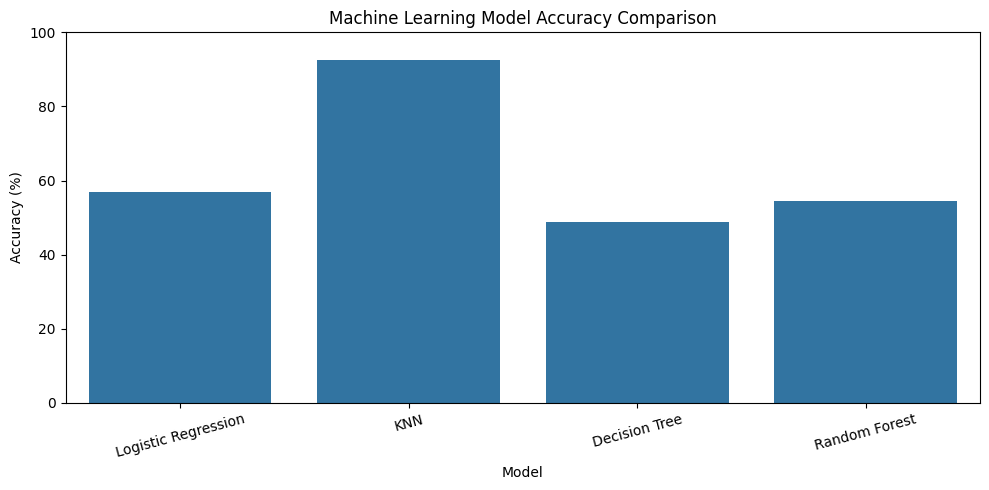


FINAL KNN PERFORMANCE
-----------------------------------------------------------------
Accuracy          : 91.01%
Macro Precision   : 65.30%
Macro Recall      : 57.85%
Macro F1 Score    : 0.5993

KNN CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

         TCP     0.9320    0.9733    0.9522      9200
     TLSv1.3     0.3740    0.1837    0.2464       800

    accuracy                         0.9101     10000
   macro avg     0.6530    0.5785    0.5993     10000
weighted avg     0.8874    0.9101    0.8957     10000



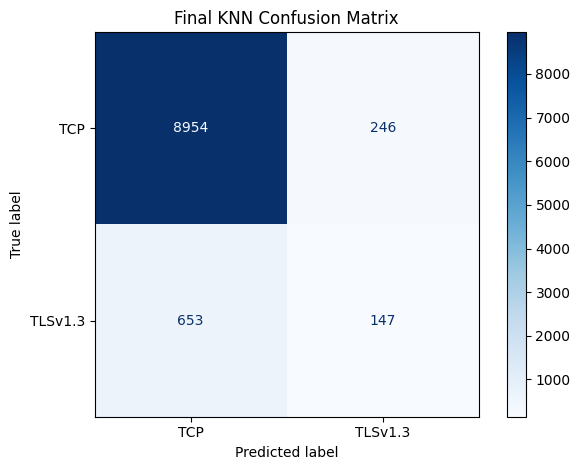


RANDOM FOREST CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

         TCP     0.9522    0.5305    0.6814      9200
     TLSv1.3     0.1139    0.6937    0.1956       800

    accuracy                         0.5436     10000
   macro avg     0.5330    0.6121    0.4385     10000
weighted avg     0.8851    0.5436    0.6426     10000



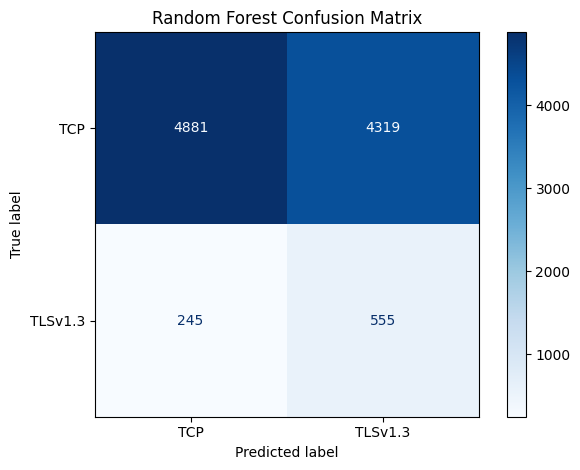


RANDOM FOREST FEATURE IMPORTANCE
-----------------------------------------------------------------


,Feature,Importance
0,Length,0.474650
2,pair_delta_ms,0.214421
4,pair_prev5_mean_length,0.140326
1,direction,0.120495
3,pair_prev_length,0.050108


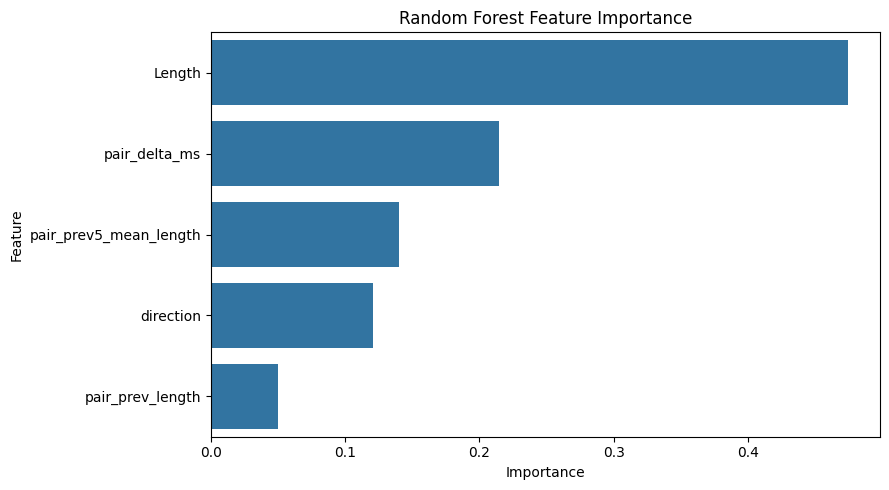


MAJORITY BASELINE COMPARISON
-----------------------------------------------------------------
Baseline Accuracy : 92.00%
KNN Accuracy      : 91.01%
Baseline Macro F1 : 0.4792
KNN Macro F1      : 0.5993

                 PROJECT CONCLUSION

The Netflix Network Traffic Classification project
successfully implemented four machine learning algorithms.

K-Nearest Neighbors achieved the best macro F1-score
among the evaluated models.

The model performs well in identifying TCP packets,
but TLSv1.3 detection remains a limitation.

Further improvements can include advanced network
features, additional datasets and model optimization.

             PROJECT EVALUATION COMPLETED
          FINAL RESULTS SAVED SUCCESSFULLY


In [27]:

# ============================================================
#       NETFLIX NETWORK TRAFFIC CLASSIFICATION
#                 FINAL PROJECT DASHBOARD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

from IPython.display import display

# ------------------------------------------------------------
# 1. FINAL KNN EVALUATION
# ------------------------------------------------------------

knn_predictions = best_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_precision = precision_score(
    y_test, knn_predictions, average='macro', zero_division=0
)
knn_recall = recall_score(
    y_test, knn_predictions, average='macro', zero_division=0
)
knn_f1 = f1_score(
    y_test, knn_predictions, average='macro', zero_division=0
)

# ------------------------------------------------------------
# 2. PROJECT INFORMATION
# ------------------------------------------------------------

print("=" * 65)
print("          NETFLIX NETWORK TRAFFIC CLASSIFICATION")
print("                    FINAL PROJECT REPORT")
print("=" * 65)

print("\nPROJECT INFORMATION")
print("-" * 65)

print("Dataset             : Netflix Network Traffic")
print("Total Records       : 4,290,778")
print("Target Variable     : Protocol")
print("Protocol Classes    : TCP, TLSv1.3")
print("Training Samples    :", len(X_train))
print("Testing Samples     :", len(X_test))
print("Features Used       :", len(features))

print("\nSELECTED MODEL")
print("-" * 65)
print("Algorithm           : K-Nearest Neighbors")

best_k = best_model.named_steps['knn'].n_neighbors

print("K Value           :", best_k)

# ------------------------------------------------------------
# 3. MODEL COMPARISON
# ------------------------------------------------------------

# Previously recorded results from the four-model experiment

comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy (%)': [
        56.95, 92.57, 48.73, 54.36
    ],
    'Precision (%)': [
        51.4055, 79.8437, 53.3132, 53.3037
    ],
    'Recall (%)': [
        54.6902, 56.8152, 61.1223, 61.2147
    ],
    'Macro F1': [
        0.4362, 0.5979, 0.4080, 0.4385
    ]
})

print("\nFOUR MODEL COMPARISON")
print("-" * 65)
display(comparison.sort_values(
    'Macro F1', ascending=False
).reset_index(drop=True))

# Model comparison graph

plt.figure(figsize=(10, 5))
sns.barplot(
    data=comparison,
    x='Model',
    y='Accuracy (%)'
)
plt.title("Machine Learning Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. FINAL KNN PERFORMANCE
# ------------------------------------------------------------

print("\nFINAL KNN PERFORMANCE")
print("-" * 65)

print(f"Accuracy          : {knn_accuracy * 100:.2f}%")
print(f"Macro Precision   : {knn_precision * 100:.2f}%")
print(f"Macro Recall      : {knn_recall * 100:.2f}%")
print(f"Macro F1 Score    : {knn_f1:.4f}")

print("\nKNN CLASSIFICATION REPORT")
print("-" * 65)

print(classification_report(
    y_test,
    knn_predictions,
    zero_division=0,
    digits=4
))

# KNN confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    cmap='Blues',
    values_format='d'
)

plt.title("Final KNN Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. RANDOM FOREST EVALUATION
# ------------------------------------------------------------

if 'rf_model' in globals() and 'X_test_rf' in globals():

    rf_predictions = rf_model.predict(X_test_rf)

    print("\nRANDOM FOREST CLASSIFICATION REPORT")
    print("-" * 65)

    print(classification_report(
        y_test_rf,
        rf_predictions,
        zero_division=0,
        digits=4
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test_rf,
        rf_predictions,
        cmap='Blues',
        values_format='d'
    )

    plt.title("Random Forest Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # Feature importance

    rf_estimator = rf_model.named_steps['model']

    importance_df = pd.DataFrame({
        'Feature': features,
        'Importance': rf_estimator.feature_importances_
    }).sort_values(
        'Importance', ascending=False
    )

    print("\nRANDOM FOREST FEATURE IMPORTANCE")
    print("-" * 65)
    display(importance_df)

    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=importance_df,
        x='Importance',
        y='Feature'
    )
    plt.title("Random Forest Feature Importance")
    plt.tight_layout()
    plt.show()

else:
    print("\nRandom Forest evaluation not available.")
    print("Run the Random Forest evaluation cell first.")

# ------------------------------------------------------------
# 6. MAJORITY BASELINE
# ------------------------------------------------------------

majority_predictions = np.full(
    len(y_test),
    y_train.mode()[0]
)

baseline_accuracy = accuracy_score(
    y_test, majority_predictions
)

baseline_f1 = f1_score(
    y_test,
    majority_predictions,
    average='macro',
    zero_division=0
)

print("\nMAJORITY BASELINE COMPARISON")
print("-" * 65)

print(f"Baseline Accuracy : {baseline_accuracy * 100:.2f}%")
print(f"KNN Accuracy      : {knn_accuracy * 100:.2f}%")
print(f"Baseline Macro F1 : {baseline_f1:.4f}")
print(f"KNN Macro F1      : {knn_f1:.4f}")

# ------------------------------------------------------------
# 7. SAVE FINAL RESULTS
# ------------------------------------------------------------

joblib.dump(
    best_model,
    '/content/Netflix_Final_KNN_Model.pkl'
)

comparison.to_csv(
    '/content/Netflix_Model_Comparison.csv',
    index=False
)

pd.DataFrame(
    classification_report(
        y_test,
        knn_predictions,
        output_dict=True,
        zero_division=0
    )
).transpose().to_csv(
    '/content/Netflix_Final_Classification_Report.csv'
)

# ------------------------------------------------------------
# 8. FINAL CONCLUSION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("                 PROJECT CONCLUSION")
print("=" * 65)

print("""
The Netflix Network Traffic Classification project
successfully implemented four machine learning algorithms.

K-Nearest Neighbors achieved the best macro F1-score
among the evaluated models.

The model performs well in identifying TCP packets,
but TLSv1.3 detection remains a limitation.

Further improvements can include advanced network
features, additional datasets and model optimization.
""")

print("=" * 65)
print("             PROJECT EVALUATION COMPLETED")
print("          FINAL RESULTS SAVED SUCCESSFULLY")
print("=" * 65)
